In [1]:
# imports
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler

from scipy import stats


# Data Preprocessing
### Includes any change made to the data before applying feature selection: imputation, normalisation, bootstrapping,

Process for CW1 went as follows:

Classification
1. One hot encoding (categorical features to binary) | Imputation (using mode, old method) 
Note: there were null values '?' that were not handled before one hot encoding
2. Normalisation (MinMax, numerical features -> 0-1 range)

Regression
1. Imputation (removed null data, mean for continuous, mode for categorical)
2. Normalisation (MinMax)
3. One hot encoding (pd.get_dummies)

Possible other methods for preprocessing include:
- Removing outliers
- VAE/Bootstrapping
    - Generating new instances from not a lot of data
        - Training data after removing outliers

And some more implicit methods include:
- Separating data into features and outcomes/labels

In [2]:
# viewing data and datatypes (numerical / categorical)
dataset = pd.read_csv("./datasets/TrainDataset2025.csv")
dataset.head(10)

,ID,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,TRG002174,1,144.0,41.0,0,0,0,1,3,3,...,0.517172,0.375126,3.325332,0.002314,3.880772e+06,473.464852,0.000768,0.182615,0.030508,0.000758
1,TRG002178,0,142.0,39.0,1,1,0,0,3,3,...,0.444391,0.444391,3.032144,0.005612,2.372010e+06,59.459710,0.004383,0.032012,0.001006,0.003685
2,TRG002204,1,135.0,31.0,0,0,0,1,2,1,...,0.534549,0.534549,2.485848,0.006752,1.540027e+06,33.935384,0.007584,0.024062,0.000529,0.006447
3,TRG002206,0,12.0,35.0,0,0,0,1,3,3,...,0.506185,0.506185,2.606255,0.003755,6.936741e+06,46.859265,0.005424,0.013707,0.000178,0.004543
4,TRG002210,0,109.0,61.0,1,0,0,0,2,1,...,0.462282,0.462282,2.809279,0.006521,1.265399e+06,39.621023,0.006585,0.034148,0.001083,0.005626
5,TRG002225,0,135.0,49.0,0,0,0,1,3,3,...,0.532369,0.532369,2.661106,0.007079,1.795207e+06,101.316642,0.002652,0.053378,0.002770,0.002263
6,TRG002228,0,139.0,56.0,0,0,0,1,3,2,...,0.513590,0.513590,2.745216,0.003993,1.142859e+07,131.839592,0.001949,0.021567,0.000446,0.001669
7,TRG002234,0,17.0,41.0,0,0,0,1,3,2,...,0.476326,0.476326,3.099632,0.008650,1.032117e+06,96.947959,0.002821,0.069697,0.004285,0.002475
8,TRG002237,0,139.0,46.0,0,0,0,1,2,1,...,0.534279,0.534279,2.515057,0.004309,2.122739e+06,26.938952,0.009552,0.021483,0.000463,0.008248
9,TRG002241,0,138.0,50.0,0,0,1,0,2,1,...,0.517795,0.517795,2.547969,0.003804,2.725950e+06,29.577853,0.008596,0.013617,0.000175,0.007353


In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Columns: 121 entries, ID to original_ngtdm_Strength
dtypes: float64(108), int64(12), object(1)
memory usage: 378.2+ KB


In [4]:
# Calculate some statistical points about the dataset columns (features and RFS target variable)
dataset.describe()

,pCR (outcome),RelapseFreeSurvival (outcome),Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.00000,...,4.000000e+02,4.000000e+02,4.000000e+02,400.000000,4.000000e+02,400.000000,400.000000,400.000000,400.000000,400.000000
mean,12.697500,56.000208,51.804674,0.547500,2.902500,2.797500,2.830000,9.875000,6.562500,8.63250,...,3.957637e-01,3.911005e-01,2.722189e+00,0.003347,5.679717e+07,178.311246,32500.032620,0.056935,0.005965,0.029322
std,111.107417,27.137584,10.948522,0.498362,49.932114,49.937068,49.935558,86.092911,70.444284,86.20034,...,1.666319e-01,1.615922e-01,7.648849e-01,0.002419,7.063846e+08,1045.453432,177545.921568,0.047179,0.008379,0.115915
min,0.000000,0.000000,23.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.00000,...,7.050000e-11,7.050000e-11,-3.200000e-16,0.000008,0.000000e+00,0.000000,0.000248,0.000000,0.000000,0.000000
25%,0.000000,38.000000,44.516769,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,1.00000,...,3.199017e-01,3.184398e-01,2.340783e+00,0.001389,1.030473e+06,18.760570,0.001826,0.018628,0.000310,0.001464
50%,0.000000,55.000000,51.019507,1.000000,0.000000,0.000000,0.000000,2.000000,1.000000,1.00000,...,4.095627e-01,4.054695e-01,2.814884e+00,0.002944,3.277334e+06,67.929659,0.004383,0.047740,0.002330,0.003276
75%,0.000000,73.000000,60.000000,1.000000,1.000000,1.000000,1.000000,3.000000,2.000000,1.00000,...,5.000049e-01,4.956920e-01,3.304411e+00,0.004798,9.079686e+06,157.370294,0.013769,0.085321,0.007962,0.009479
max,999.000000,144.000000,79.603012,1.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.00000,...,8.773779e-01,8.571429e-01,4.947427e+00,0.011301,1.390001e+10,20764.693790,1000000.000000,0.285100,0.060742,1.145601


In [6]:
# Split data into features and target variable for the regression task

## Target variable
y = dataset['RelapseFreeSurvival (outcome)']

## Features
x = dataset.drop(['ID', 'pCR (outcome)', 'RelapseFreeSurvival (outcome)'], axis = 1)


In [19]:
print(x.select_dtypes(np.int64))

print("Before: "+str(x.select_dtypes(np.int64).shape))

#x['Age'] = x['Age'].astype(np.int64)

x['original_shape_VoxelVolume'] = x['original_shape_VoxelVolume'].astype(np.float64)


print("After: "+str(x.select_dtypes(np.int64).shape))

# Save column names of categorical features (clinical)
categorical_names = x.select_dtypes(np.int64).columns
categorical_names



     ER  PgR  HER2  TrippleNegative  ChemoGrade  Proliferation  HistologyType  \
0     0    0     0                1           3              3              1   
1     1    1     0                0           3              3              1   
2     0    0     0                1           2              1              1   
3     0    0     0                1           3              3              1   
4     1    0     0                0           2              1              1   
..   ..  ...   ...              ...         ...            ...            ...   
395   1    0     1                0           3              2              1   
396   0    0     0                1           3              3              1   
397   0    0     0                1           2              1              1   
398   1    0     0                0           3              3              1   
399   1    0     0                0           2              1              1   

     LNStatus  TumourStage 

Index(['ER', 'PgR', 'HER2', 'TrippleNegative', 'ChemoGrade', 'Proliferation',
       'HistologyType', 'LNStatus', 'TumourStage', 'Gene'],
      dtype='object')

## Type-specific preprocessing
### Dataset datatypes include: object, float64 and int64
    # object: ID Column
    # float64: Continuous features
    # int64: Categorical features

### Handling object datatype
1. Remove object datatype

This only contains the ID column

In [4]:
# Handling object datatype
#print(dataset_x_all.select_dtypes(object)) # ID Column

#print("Before: "+str(dataset_x_all.select_dtypes(object).shape))

#dataset_x_all = dataset_x_all.drop("ID",axis=1)
#print("After: "+str(dataset_x_all.select_dtypes(object).shape))


### Handling int64 datatype
#### Categorical Features
1. Remove non-categorical features

'original_shape_VoxelVolume' feature is int, but seems it should be float like the rest of the medical imaging features


### Handling float64 datatype
#### Continuous Features

Age is considered a continuous feature as there are continuous values in the dataset
- Considered converting to int, but this would truncate potentially valuable data and lead to Curse of Dimensionality if using an encoding technique later on.

In [20]:
# Save column names of continuous features (medical imaging, and age)
x['original_shape_VoxelVolume'] = x['original_shape_VoxelVolume'].astype(np.float64)
continuous_names = x.select_dtypes(np.float64).columns
continuous_names

Index(['Age', 'original_shape_Elongation', 'original_shape_Flatness',
       'original_shape_LeastAxisLength', 'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter', 'original_shape_MeshVolume',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],
      dtype='object', length=108)

## General Preprocessing
1. Handling '999' values
2. Balancing Data (Frequency Handling)
3. Train-Test Split
4. Outlier Handling
5. Data Imputation
6. a - Data Normalisation | b - One-Hot Encoding

In [9]:
x[categorical_names]

,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,Gene
0,0,0,0,1,3,3,1,1,2,1
1,1,1,0,0,3,3,1,1,2,0
2,0,0,0,1,2,1,1,0,2,1
3,0,0,0,1,3,3,1,1,3,1
4,1,0,0,0,2,1,1,0,2,1
...,...,...,...,...,...,...,...,...,...,...
395,1,0,1,0,3,2,1,1,4,0
396,0,0,0,1,3,3,1,0,2,0
397,0,0,0,1,2,1,1,0,2,0
398,1,0,0,0,3,3,1,1,3,0


### 1. Handling 999 values
Issue: Can't replace all '999' with np.nan. This converts int64 to float64 as NaN is float64
- Solution: by saving column names, in datatype-specific handling, for int64 (categorical) features, no longer a need to preserve int64 as no data is lost when converting to float

In [10]:
# Replace 999 (placeholder) with NaN
x = x.replace([999],np.nan)

# Viewing features with null values
missing_values = x.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

### 2. Balancing Data

### 3. Train-test split

In [21]:
# Split the dataset into 80% for training data and 20% for testing data, with a specified random state
r_state = 12
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = r_state)
X_train

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
199,36.783025,0,1,0,0,3,3,1,0,3,...,0.350799,0.350799,3.197160,0.003696,9.762004e+05,74.501409,0.004012,0.102368,0.011175,0.003570
43,69.000000,0,0,1,0,2,1,1,1,2,...,0.550507,0.550507,2.573220,0.005959,1.052641e+06,21.346044,0.012082,0.024663,0.000567,0.010516
307,60.000000,0,0,0,1,2,1,1,1,1,...,0.426840,0.426840,2.956748,0.007522,4.830177e+05,38.839662,0.007064,0.066551,0.004116,0.006365
166,38.143737,1,1,1,0,3,2,1,0,2,...,0.572002,0.572002,2.000000,0.002920,1.720824e+06,8.240840,0.030818,0.011843,0.000150,0.025057
64,45.653662,0,0,1,0,3,2,1,0,3,...,0.584634,0.583599,2.398050,0.002764,1.202316e+07,163.782516,0.001637,0.033111,0.001479,0.001571
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,71.300000,0,0,0,1,3,3,1,1,2,...,0.411956,0.411956,3.573921,0.004671,8.211440e+06,448.101792,0.000618,0.073363,0.005057,0.000545
253,63.238877,0,0,1,0,2,3,1,1,3,...,0.409377,0.409376,3.305045,0.001730,6.755623e+06,476.373341,0.000653,0.117835,0.014701,0.000594
390,68.400000,0,0,0,1,3,2,1,1,2,...,0.476508,0.476508,2.755023,0.004610,1.456280e+06,34.211090,0.007661,0.035392,0.001197,0.006756
155,40.000000,1,1,0,0,2,1,1,1,3,...,0.404660,0.404660,3.386250,0.003987,2.235835e+06,104.017827,0.002675,0.070976,0.005043,0.002376


In [32]:
# Create a copy of the training set of the features for exploring and analysing the data
X_train_eda = X_train.copy()

<Axes: >

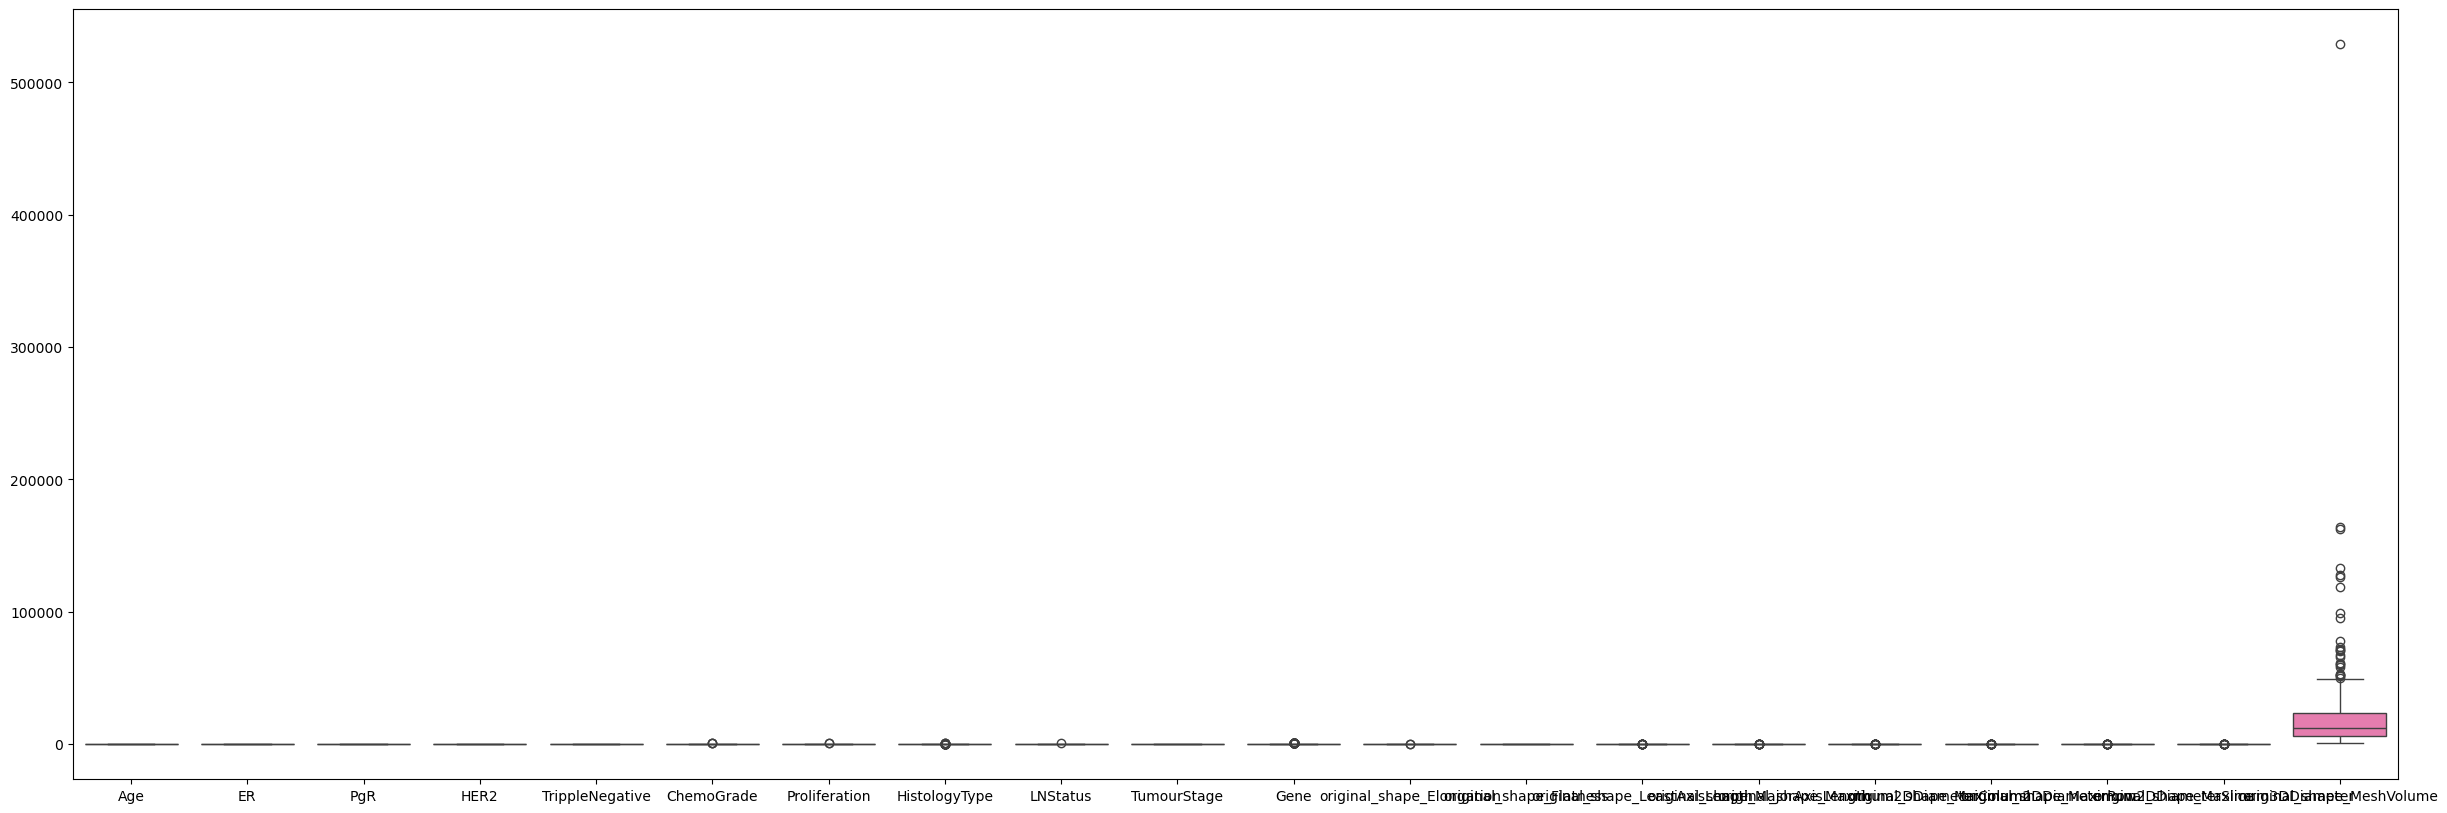

In [34]:
# Visualise the data ranges of some of the features. Here, we just selected the first 20 features
fig, ax = plt.subplots(1, figsize = (30, 10))
sns.boxplot(data = X_train_eda.iloc[:, :20], ax = ax)

<Axes: >

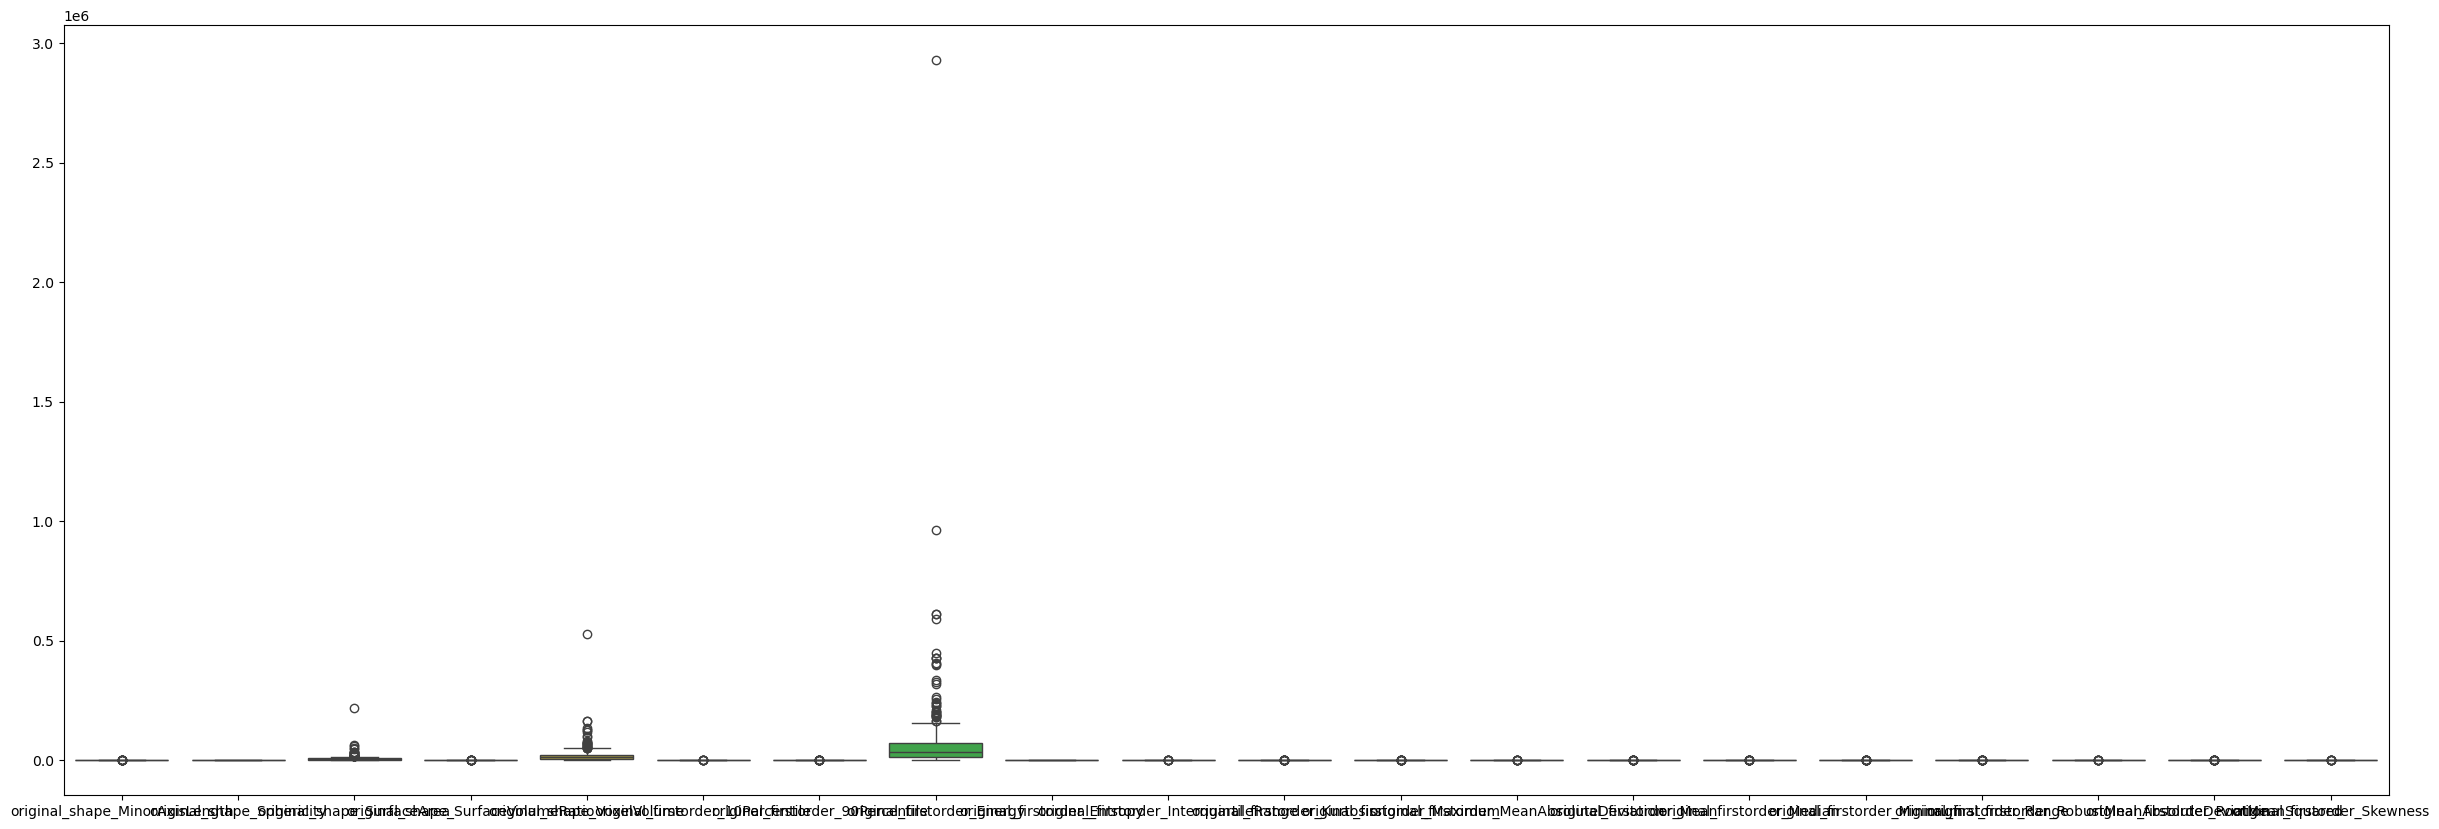

In [31]:
# Visualise the data ranges of some of the other features. Here, we selected the the next 20 features following from the first 20
fig, ax = plt.subplots(1, figsize = (30, 10))
sns.boxplot(data = X_train_eda.iloc[:, 20:40], ax = ax)

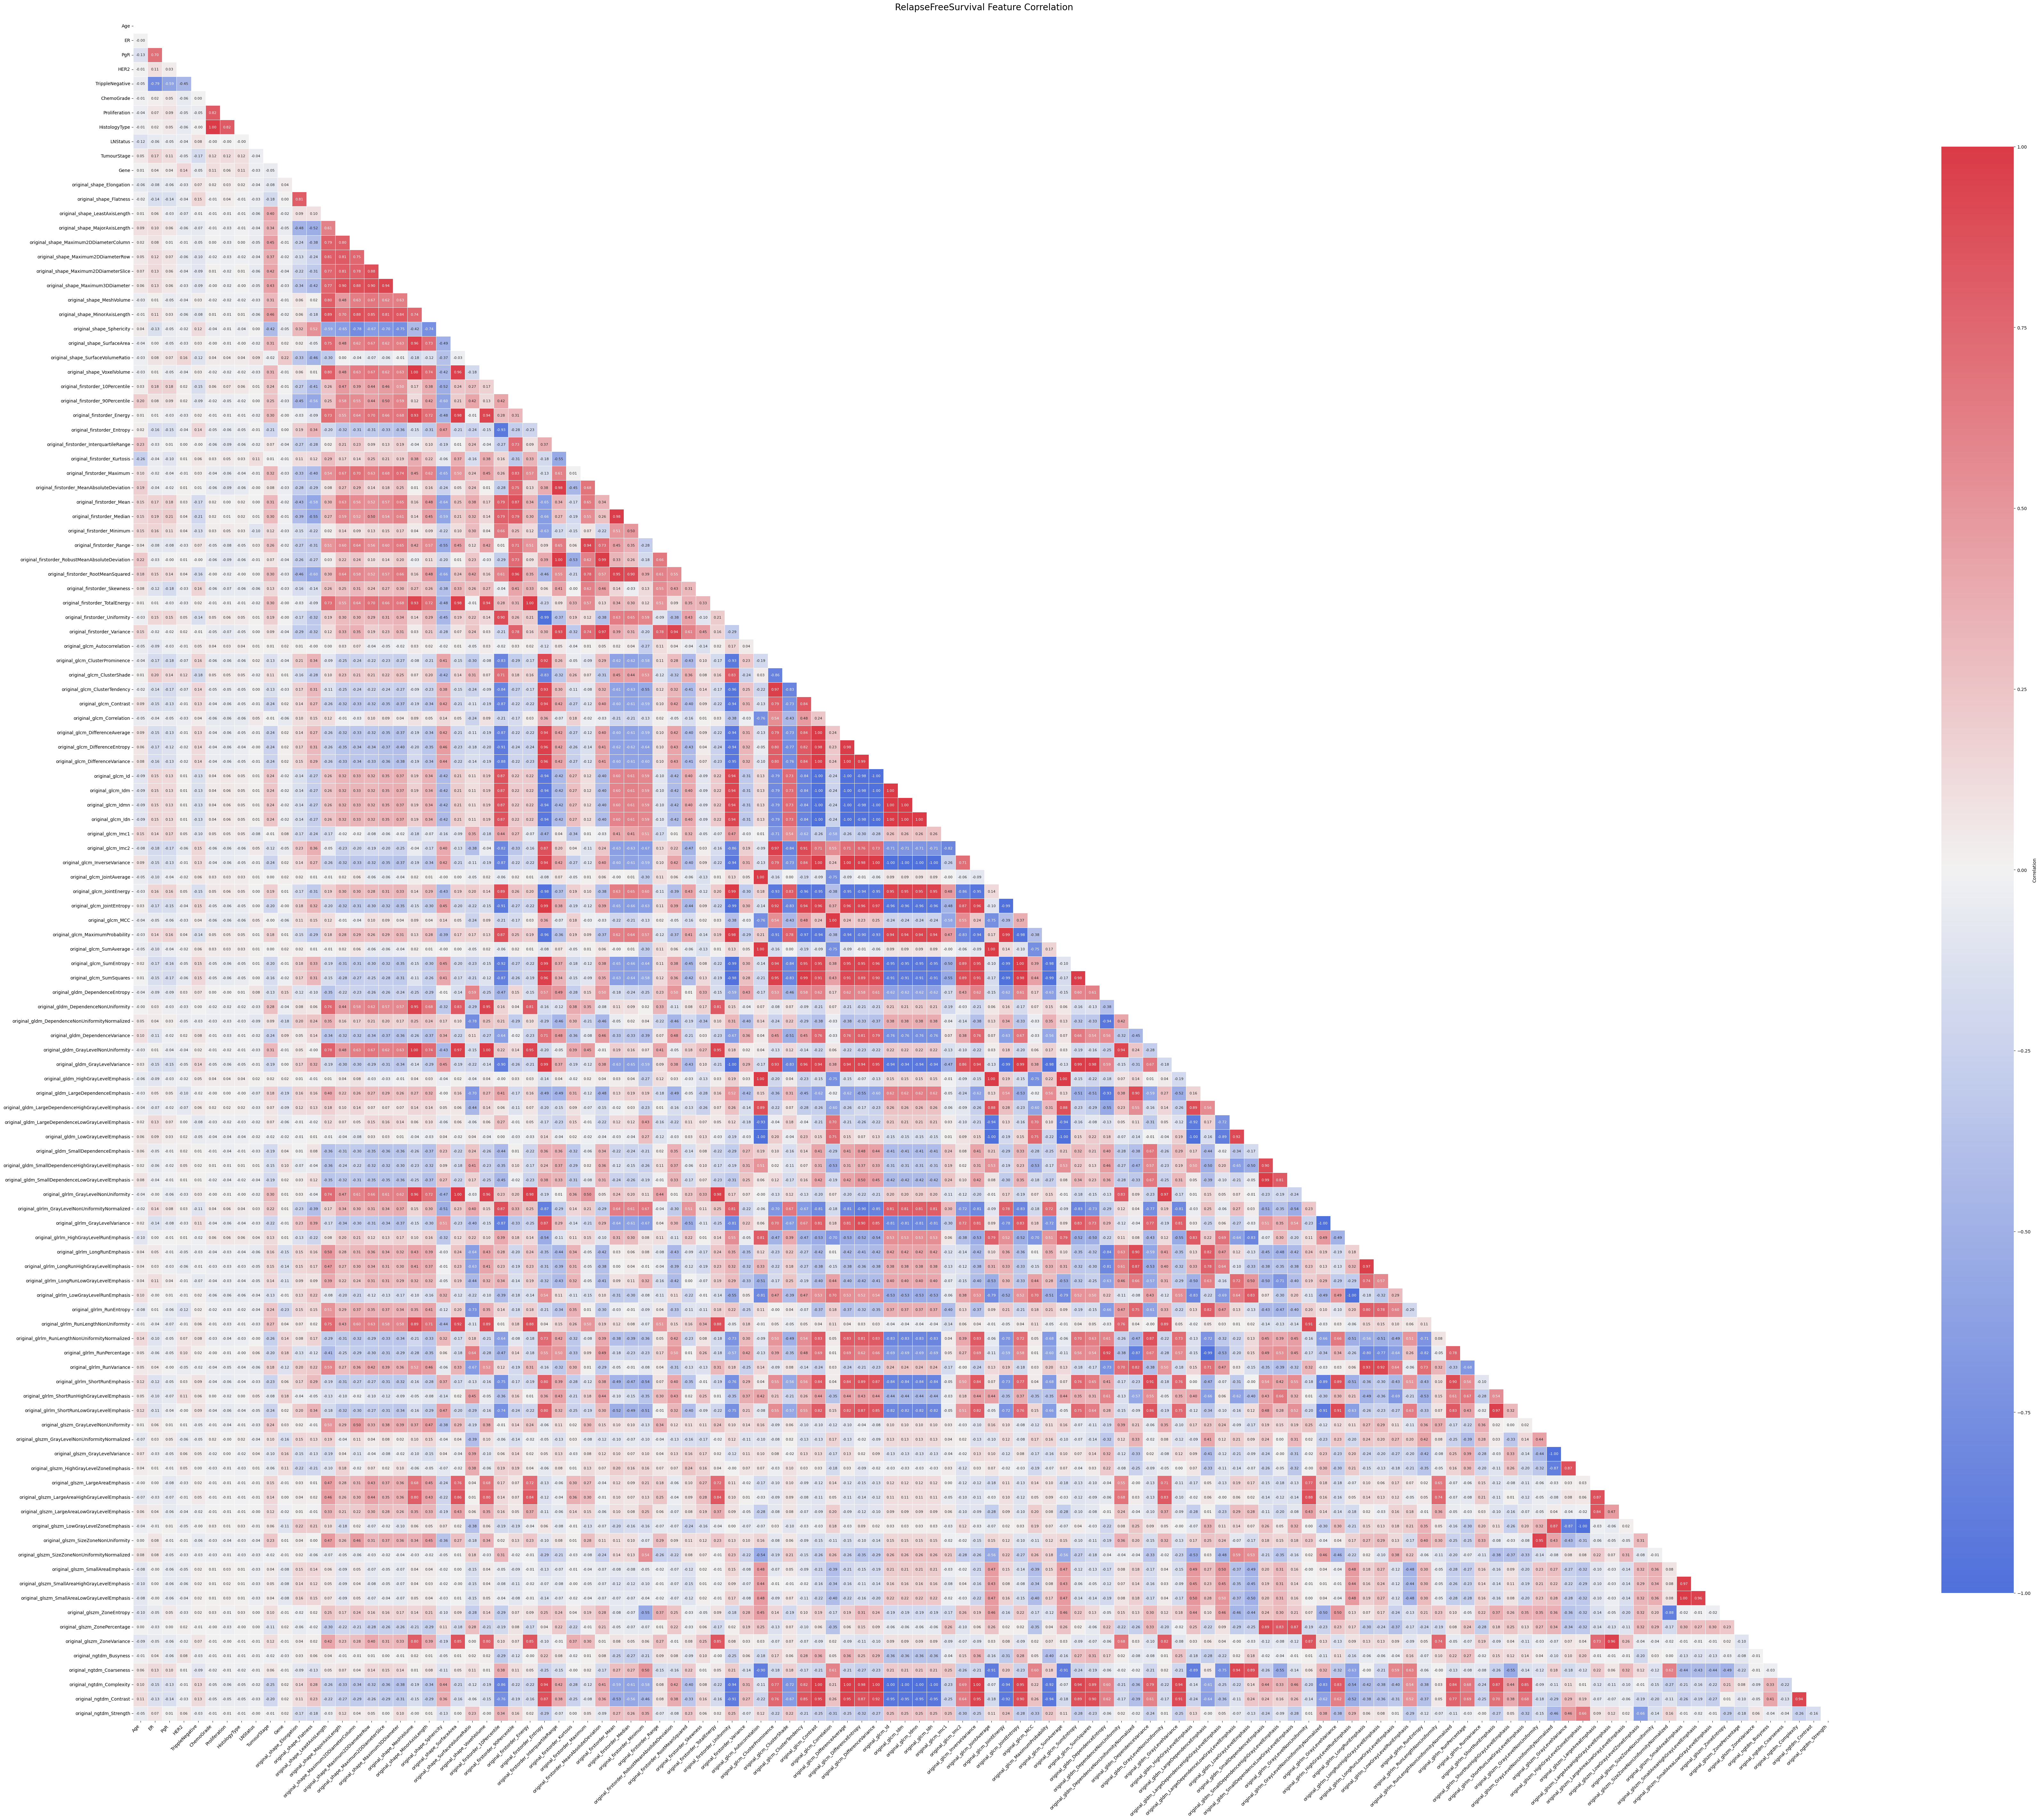

In [35]:
# Perform correlation analyis on the features
corrMatt = X_train_eda.corr(numeric_only=True)
# Generate a mask for the upper triangle
mask = np.zeros_like(corrMatt)
mask[np.triu_indices_from(mask)] = True

# Set up the matplotlib figure
# Calculate a dynamic figure size based on number of features
n_features = len(categorical_names) + len(continuous_names)
fig_width = max(20, n_features * 0.6)  # At least 20, or 0.6 per feature
fig_height = max(16, n_features * 0.5)  # At least 16, or 0.5 per feature
fig, ax = plt.subplots(figsize=(fig_width, fig_height))

plt.title('RelapseFreeSurvival Feature Correlation', fontsize = 20, pad = 20)

# Generate a custom diverging colour map
cmap = sns.diverging_palette(260, 10, as_cmap=True)

# Draw the heatmap with improved settings
sns.heatmap(corrMatt, 
            vmax = 1.0,           # Set maximum for diverging colour map
            vmin = -1.0,          # Set minimum for diverging colur map
            square = True,        # Changed to True for better appearance
            cmap = cmap, 
            mask = mask,
            ax = ax, 
            annot = True,         # Show correlation values
            fmt = '.2f',          # Two decimal places
            linewidths = 0.5,     
            linecolor = 'white',  # White grid lines
            cbar_kws = {"shrink": 0.8, "label": "Correlation"},  # Better colourbar
            annot_kws = {"fontsize": 8}) 

# Rotate labels for better readability
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

# Adjust layout to prevent label cutoff
plt.tight_layout()

plt.show()

In [ ]:
X_train_transformed = X_train.copy()

In [16]:
# Check if there are any duplicate rows in the training data. If there are, keep the first occurence of that row and drop the other occurences
duplicate_rows = X_train_transformed[X_train_transformed.duplicated()]
print("Duplicate rows found:", duplicate_rows)

Duplicate rows found: Empty DataFrame
Columns: [Age, ER, PgR, HER2, TrippleNegative, ChemoGrade, Proliferation, HistologyType, LNStatus, TumourStage, Gene, original_shape_Elongation, original_shape_Flatness, original_shape_LeastAxisLength, original_shape_MajorAxisLength, original_shape_Maximum2DDiameterColumn, original_shape_Maximum2DDiameterRow, original_shape_Maximum2DDiameterSlice, original_shape_Maximum3DDiameter, original_shape_MeshVolume, original_shape_MinorAxisLength, original_shape_Sphericity, original_shape_SurfaceArea, original_shape_SurfaceVolumeRatio, original_shape_VoxelVolume, original_firstorder_10Percentile, original_firstorder_90Percentile, original_firstorder_Energy, original_firstorder_Entropy, original_firstorder_InterquartileRange, original_firstorder_Kurtosis, original_firstorder_Maximum, original_firstorder_MeanAbsoluteDeviation, original_firstorder_Mean, original_firstorder_Median, original_firstorder_Minimum, original_firstorder_Range, original_firstorder_Robu

### 4. Outlier Removal
Options: 
1. Z-Score
2. Interquartile Range

[Other Model-based methods:](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/)

3. Isolation Forest
4. Local Outlier Factor
5. DBSCAN(?)

[Even More Model-based Methods](https://scikit-learn.org/stable/modules/outlier_detection.html#:~:text=OK-,2.7.1.%20Overview%20of%20outlier%20detection%20methods,-%23)

In [77]:
# Data visualisation
#scaler = MinMaxScaler()

# Boxplot below shows normalised continuous features + outliers
#fig,ax=plt.subplots(1,figsize=(20,8))
#sns.boxplot(data=scaler.fit_transform(X_train[continuous_names]),ax=ax)

Note: Above boxplot, categorical features normalised to 0-1 range, shows prevalence of outliers. Handling using naive methods, such as Z-score or IQR, may be ineffective

##### Option 1 - Z-score

In [78]:
# Outlier Total
z_scores = np.abs(stats.zscore(X_train_transformed))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))

# # Outlier Locations

# for index in outlier_indices:
#    print(index)

Outlier total: 478


In [79]:
# Applying z-score

X_train_transformed[(np.abs(stats.zscore(X_train_transformed)) < 3).all(axis=1)] # < 3 checks for rows where all features are 3 standard deviations from the mean

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength


Note: Z-score is clearly ineffective. Implication from above cell is that outliers are prevalent in all samples, hence they are all removed

##### Option 2 - Interquartile Range

In [80]:
# Calculating Interquartile Range
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

In [81]:
# Outputting number of outliers per column
outliers_iqr = ((X_train_transformed < (Q1 - 1.5 * IQR)) | (X_train_transformed > (Q3 + 1.5 * IQR)))

print("Number of outliers per column: (Top 5)")
outliers_col = outliers_iqr.sum()
outliers_col = outliers_col[outliers_col > 0].sort_values(ascending = False)

print(outliers_col.head())

Number of outliers per column: (Top 5)
original_ngtdm_Coarseness                       51
original_ngtdm_Strength                         48
original_glszm_LargeAreaLowGrayLevelEmphasis    45
original_glszm_LargeAreaEmphasis                43
original_glszm_ZoneVariance                     42
dtype: int64


Note: Using IQR presents a similar issue with z-score as there are likely outliers across many rows. To avoid this, outliers are replaced with the median instead of removing the entire row.

In [82]:
# Create a function to handle outliers in columns of either categorical or continuous features using Interquartile Range of the columns
def outlier_iqr(X_df: pd.DataFrame, columns: pd.Index):
    
    for col in columns:
        lower_quartile = X_df[col].quantile(0.25)
        upper_quartile = X_df[col].quantile(0.75)
        iqr = upper_quartile - lower_quartile

        lower_bound = lower_quartile - 1.5 * iqr
        upper_bound = upper_quartile + 1.5 * iqr
        
        # where a value is an outlier
            # replace it with the median
        X_df[col] = np.where((X_df[col] < lower_bound) | (X_df[col] > upper_bound), X_df[col].median(), X_df[col])

outlier_iqr(X_df = X_train_transformed, columns = continuous_names)

In [83]:
# Printing outlier locations
z_scores = np.abs(stats.zscore(X_train_transformed))
outliers_zscore = np.where(z_scores > 3)
outlier_indices = list(zip(outliers_zscore[0], outliers_zscore[1]))

print("Outlier total: "+str(len(outlier_indices)))

# print("\nOutlier Locations: ")
# for index in outlier_indices:
#     print(index)

Outlier total: 161


##### Option 3 - Isolation Forest
Method of anomaly detection that isolates outliers by building decision trees based on multiple splits. Supposedly better for high dimensions [[reference]](https://www.geeksforgeeks.org/machine-learning/machine-learning-outlier/#:~:text=IQR%20Method-,3.%20Isolation%20Forest,-Isolation%20Forest%20is)

Params include: contamination, random state and bootstrap [(among others that may be useful)](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html#:~:text=IsolationForest-,IsolationForest,-%23)
- contamination (float) is the percentage of outliers
- random state (int) is the pseudorandom seed
- bootstrap (bool) is an option to enable random sampling with replacement

In [84]:
#from sklearn.ensemble import IsolationForest

#iso = IsolationForest(contamination=0.05, random_state=42, bootstrap=True)
#y_pred_iso = iso.fit_predict(X_train)

#X_train["IsoForest_Outlier"] = y_pred_iso
#print(X_train["IsoForest_Outlier"].value_counts())

#plt.figure(figsize=(7, 5))
#sns.scatterplot(x="original_shape_Elongation", y="RelapseFreeSurvival (outcome)", data=X_train,
#                hue="IsoForest_Outlier", palette="coolwarm")
#plt.title("Isolation Forest Outlier Detection")
#plt.show()

Index(['RelapseFreeSurvival (outcome)', 'Age', 'original_shape_Elongation',
       'original_shape_Flatness', 'original_shape_LeastAxisLength',
       'original_shape_MajorAxisLength',
       'original_shape_Maximum2DDiameterColumn',
       'original_shape_Maximum2DDiameterRow',
       'original_shape_Maximum2DDiameterSlice',
       'original_shape_Maximum3DDiameter',
       ...
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_glszm_SmallAreaLowGrayLevelEmphasis',
       'original_glszm_ZoneEntropy', 'original_glszm_ZonePercentage',
       'original_glszm_ZoneVariance', 'original_ngtdm_Busyness',
       'original_ngtdm_Coarseness', 'original_ngtdm_Complexity',
       'original_ngtdm_Contrast', 'original_ngtdm_Strength'],

### 5. Data Imputation
Performed after outlier handling as imputation should perform better with clean(er) data, especially for null values

Null values can be removed or imputed, or a combination of both consider only removing Gene null values, as other null totals are [minimal](#1-null-handling)  
- SimpleImputer for imputation by mean/mode/median
- IterativeImputer for model-based imputation

##### SimpleImputer

Options:
1. Removal of all null values
2. Partial Removal, Partial Imputation
3. Imputation of all null values

This has a 'missing_values' field, meaning we could set said field to 999 instead of the earlier conversion of 999 to NaN
- Prefer not to do so as '999' would negatively affect the distribution of data used in the models

In [88]:
# Viewing features with null values
print("Before Imputation: ")
missing_values = X_train_transformed.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

Before Imputation: 


PgR                 1
HER2                1
TrippleNegative     1
ChemoGrade          3
Proliferation       2
HistologyType       3
LNStatus            1
Gene               88
dtype: int64

In [91]:
# Impute missing values which is np.nan by default
imputer_mean = SimpleImputer(strategy = 'mean')
imputer_median = SimpleImputer(strategy = 'median')
imputer_mode = SimpleImputer(strategy = 'most_frequent')

##### k-NN Imputation



[This](https://scikit-learn.org/stable/modules/impute.html#multiple-vs-single-imputation:~:text=of%20IterativeImputer.-,7.4.3.2.%20Multiple%20vs.%20Single%20Imputation,-%23) might be helpful

##### Imputation of all null values
Imputing continuous|categorical features using either:
1. Mean|Mode
2. Median|Mode (Selected Transformation)

Mean|Mode Imputation

In [93]:
# X_train[continuous_names] = imputer_mean.fit_transform(X_train[continuous_names])
# X_train[categorical_names] = imputer_mode.fit_transform(X_train[categorical_names])

Median|Mode Imputation

(Median is less sensitive to outliers)

In [94]:
# For the continuous features, impute the missing values in each column with the median of that column
X_train_transformed[continuous_names] = imputer_median.fit_transform(X_train_transformed[continuous_names])
X_train_transformed[continuous_names]

In [95]:
# For the categorical features, impute the missing values in each column with the mode of that column
X_train_transformed[categorical_names] = imputer_mode.fit_transform(X_train_transformed[categorical_names])
X_train_transformed[categorical_names]

In [97]:
# Check if there any remaining null values after data imputation

missing_values = X_train_transformed.isnull().sum()
missing_values = missing_values[missing_values > 0]
missing_values

Series([], dtype: int64)

### 5. a - Standardisation

#### Z-Score Normalisation (Standardisation)

<Axes: >

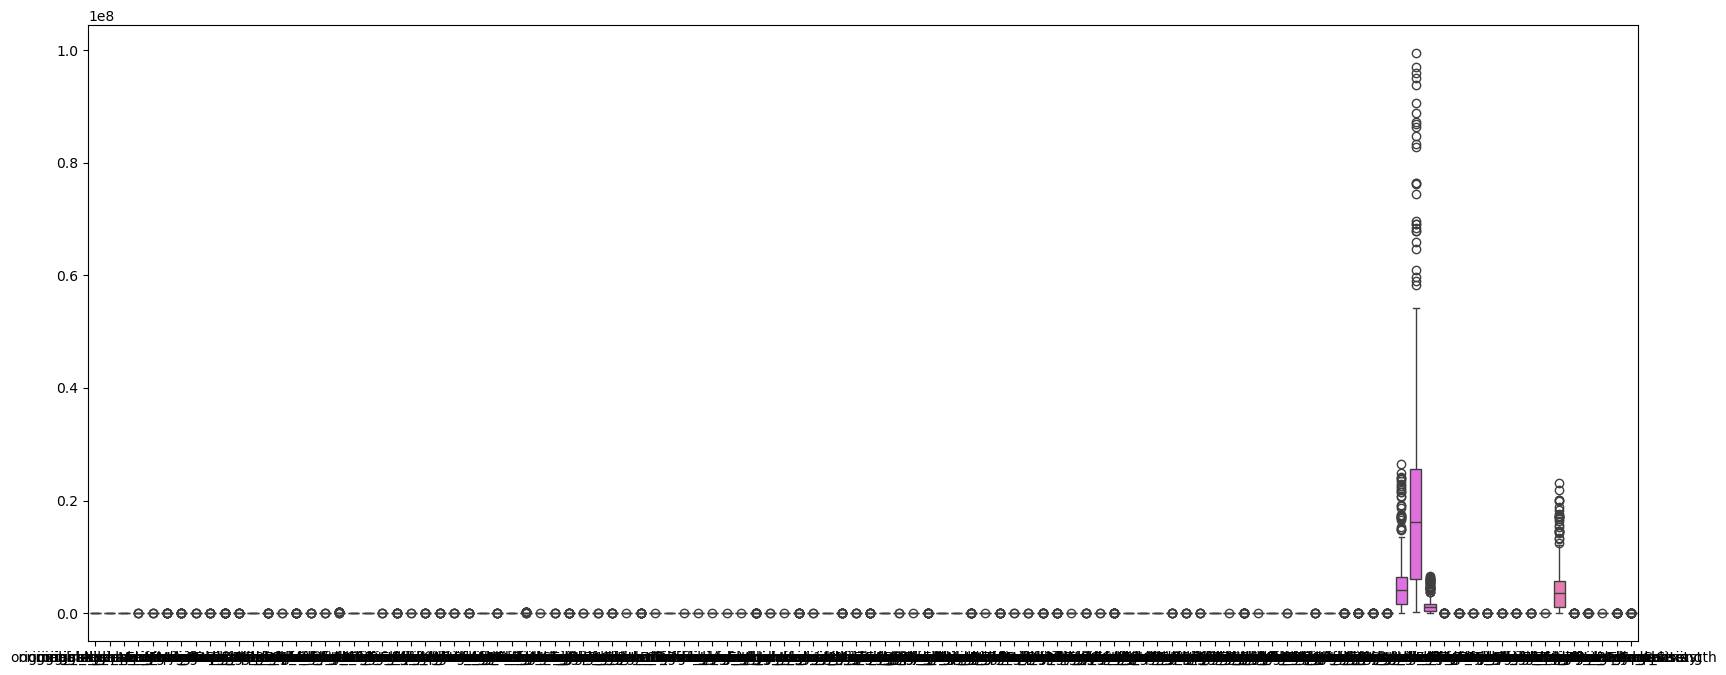

In [85]:
# View the data distribution before standardising the continuous features
fig, ax = plt.subplots(1, figsize = (20, 8))
sns.boxplot(data = X_train_transformed[continuous_names], ax = ax)

<Axes: >

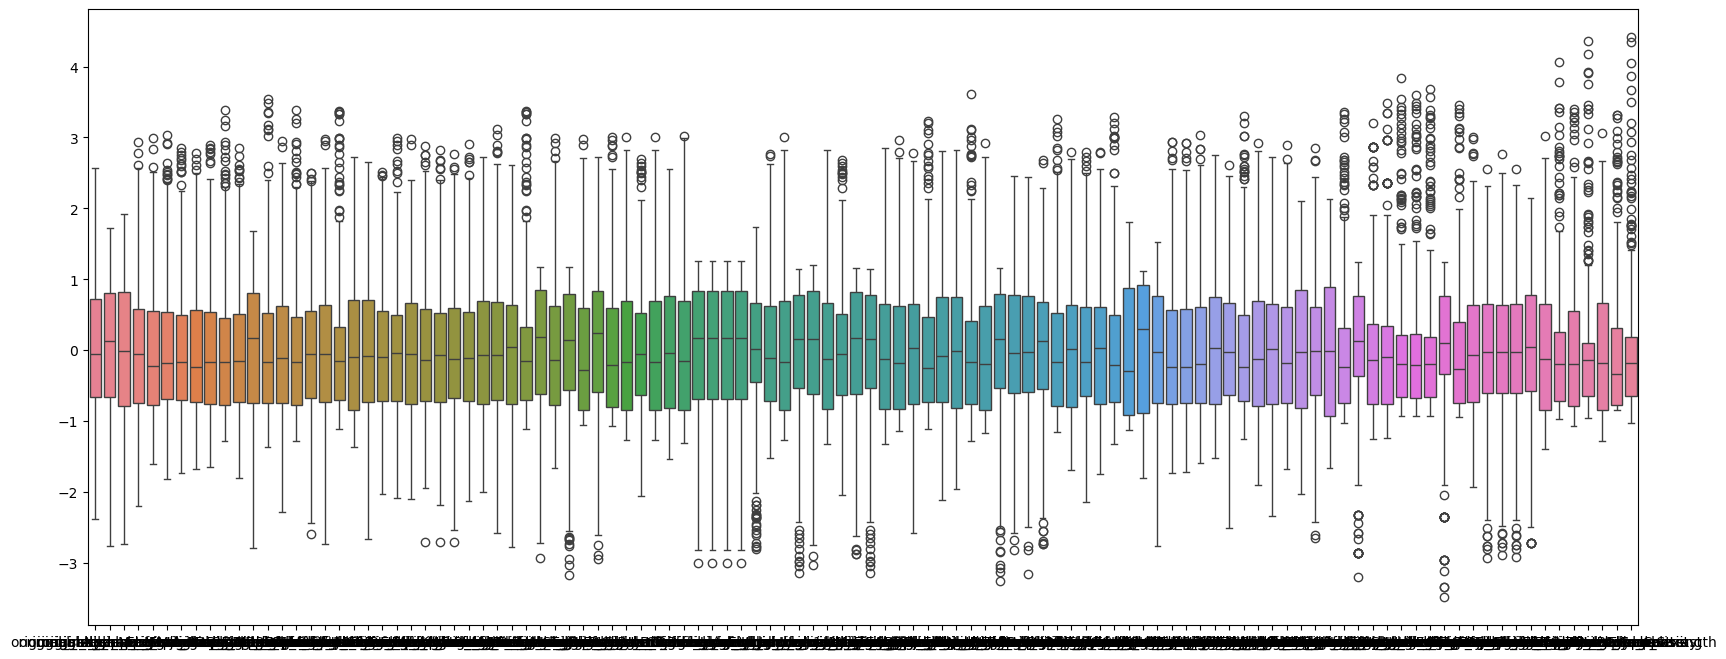

In [86]:
#scaler = MinMaxScaler()
#X_train[continuous_names] = scaler.fit_transform(X_train[continuous_names])
#X_train[continuous_names]

# Apply standardization on the continuous features
standard_scaler = StandardScaler()
X_train_transformed[continuous_names] = standard_scaler.fit_transform(X_train_transformed[continuous_names])

fig,ax=plt.subplots(1,figsize=(20,8))
sns.boxplot(data = X_train_transformed[continuous_names], ax = ax)

In [87]:
# Check the new values of the continuous features after applying the transformation
X_train_transformed[continuous_names]

,Age,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter,original_shape_MeshVolume,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
199,-1.380534,0.898274,1.661433,-0.587727,-1.139421,-1.154646,-0.984168,-1.186815,-1.193097,-0.870068,...,-0.493052,-0.480377,0.620345,0.279657,-0.752892,-0.121667,-0.202807,1.116491,1.567155,-0.085725
43,1.595167,-0.443542,-0.029533,-0.717309,-0.664226,-0.591134,-0.731139,-0.757427,-0.778187,-0.693184,...,1.174418,1.218041,-0.328280,1.309805,-0.736242,-0.793879,1.403109,-0.705976,-0.722943,1.760640
307,0.763888,-0.226057,-0.376807,-0.838082,-0.574954,-0.780682,-0.492597,-0.493390,-0.568589,-0.933196,...,0.141850,0.166308,0.254827,2.021119,-0.860315,-0.572652,0.404677,0.276446,0.043373,0.657231
166,-1.254853,0.886872,0.244935,-0.957499,-0.945122,-0.857389,-0.809128,-0.924433,-0.994481,-0.812038,...,1.353887,1.400841,-1.199790,-0.073708,-0.590702,-0.959609,-0.142971,-1.006666,-0.812883,-0.167677
64,-0.561203,-0.042835,-1.175248,0.602492,1.628266,2.371606,1.698173,2.017549,1.626700,2.202099,...,1.459361,1.499472,-0.594603,-0.144712,1.653305,1.007396,-0.675463,-0.507850,-0.525918,-0.617153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
241,1.807605,-0.169088,0.466407,2.296408,1.011058,1.304077,1.728747,1.136921,0.987704,2.900103,...,0.017583,0.039735,1.193163,0.723511,0.823054,-0.192427,-0.878133,0.436210,0.246346,-0.889807
253,1.063044,-1.465934,-1.623170,0.246160,2.149142,2.051182,2.144386,0.762450,1.348944,1.167602,...,-0.003951,0.017791,0.784371,-0.615051,0.505955,-0.192427,-0.871280,1.479243,2.328224,-0.876859
390,1.539748,-1.884752,-1.041183,-0.661181,0.093464,0.187532,-0.088172,-0.953975,-0.087678,-0.633209,...,0.556560,0.588715,-0.051871,0.695400,-0.648323,-0.631185,0.523439,-0.454338,-0.586828,0.761262
155,-1.083400,-1.164100,-0.901945,-0.327434,0.285013,-0.143933,0.181964,-0.321715,0.070393,-0.326098,...,-0.043342,-0.022320,0.907833,0.412097,-0.478524,0.251602,-0.468822,0.380220,0.243372,-0.403176


#### 5. b - One-Hot Encoding
##### (No Longer Performing due to it being redundant given the categorical features are already in numeric form)

In [98]:
# Apply One-Hot Encoding to the columns for the categorical features
#X_train_encoded = pd.get_dummies(X_train, columns = categorical_names, drop_first = True)
#X_train_encoded

#print(f"Before: {X_train.shape}\nAfter: {X_train_encoded.shape}")

In [99]:
#print(categorical_names)
#print(X_train_encoded.select_dtypes(bool).columns)

In [100]:
# Check that there are no longer any missing values for the features of each data point
#missing_values = X_train.isnull().sum()
#missing_values = missing_values[missing_values > 0]
#missing_values

In [101]:
#X_train.to_csv("./datasets/PreProcessedDataset.csv",index=False)

# Feature Selection / Dimensionality reduction
### Note: specification says to keep the following features: 'ER', 'HER2' and 'Gene' 

Feature Selection
- Wrapper methods: forward feature selection, recursive feature elimination
- Embedded methods: LASSO, Decision Trees
- Filter based methods: t-tests, chi square, univariate ANOVA, correlation analysis, idk what else slides say


Dimensionality Reduction
- Includes: PCA, LDA, manifold learning
- Is manifold learning even applicable? 


First do Correlation analysis for visualisation: https://www.geeksforgeeks.org/machine-learning/data-preprocessing-machine-learning-python/#:~:text=Step%205%3A%20Correlation%20Analysis

- Also other methods in lab probably

### Feature Selection
Feature Selection aims to create a subset of the original features optimal for the model building process. This is split into 3 categories.
- Wrapper Methods
- Embedded Methods
- Filter-based Methods

##### Wrapper Methods
These likely take too long as they iterate through different feature permutations and evaluate them using an evaluation metric. Possibly apply after another method that has already reduced the number of features.

Options:
1. Forward Feature Selection
2. Recursive Feature Elimination



In [102]:
# Forward Feature Selection
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.neighbors import KNeighborsRegressor

knr = KNeighborsRegressor(n_neighbors = 3)

sfs = SequentialFeatureSelector(knr, n_features_to_select = 10, direction = 'forward')
#sfs = sfs.fit(X_train_encoded, y_train)
sfs = sfs.fit(X_train_transformed, y_train)

cols_sfs = X_train_transformed.columns[sfs.get_support()]
#cols_sfs = X_train_encoded.columns[sfs.get_support()]
print(f"Top 10 Forward Selection Features:\n{cols_sfs.tolist()}")



Top 10 Forward Selection Features:
['ER', 'PgR', 'HER2', 'TrippleNegative', 'original_shape_Maximum2DDiameterColumn', 'original_shape_Maximum2DDiameterRow', 'original_glszm_LargeAreaEmphasis', 'original_glszm_LargeAreaHighGrayLevelEmphasis', 'original_glszm_ZoneVariance', 'original_ngtdm_Strength']


In [103]:
# Recursive Feature Elimination
#from sklearn.feature_selection import RFE
#from sklearn.linear_model import LinearRegression

#estimator = LinearRegression()

#selector_rfe = RFE(estimator, n_features_to_select = 10, step = 1)
#selector_rfe.fit(X_train, y_train)

#cols_rfe = X_train.columns[selector_rfe.get_support()]
#print(f"Top 10 Recursive Feature Elimination Features:\n{cols_rfe.tolist()}")
#selected_features = rfe.support_

#print("Remaining Features:\n", list(X_train.columns[selected_features]))



##### Embedded Methods
Embed Feature Selection into the model process. Should probably use in the ML Method Development process.

Options:
1. LASSO (Regression)
2. Decision Trees / Random Forest

In [104]:
# LASSO Regression
#from sklearn.linear_model import Lasso
#from sklearn.feature_selection import SelectFromModel

# Alpha controls regularization strength (higher alpha -> fewer features selected)
#lasso = Lasso(alpha = 0.01)
#lasso.fit(X_train, y_train) # Using regression target here

#lasso_model = SelectFromModel(lasso, prefit = True)

#selected_features = pd.DataFrame({'Feature': X_train.columns, 'Selected': lasso_model.get_support()})
#print(selected_features[selected_features['Selected'] == True])

# Select features with non-zero weights
#lasso_coefs = pd.Series(np.abs(lasso.coef_), index = X_train.columns)
#print(f"Top 10 LASSO Features (Regression):\n{lasso_coefs.nlargest(10)}")

In [105]:
# Random Forest
#from sklearn.ensemble import RandomForestRegressor
#rf_model = RandomForestRegressor(n_estimators = 100, random_state = r_state)
#rf_model.fit(X_train, y_train)

# Extract feature importances
#importances = rf_model.feature_importances_

#feature_importance_df = pd.DataFrame({'Feature': X_train.columns, 'Importance': importances})
#print(feature_importance_df.sort_values(by='Importance', ascending=False))

# Extract feature importances
#feature_importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
#print(f"Top RF Features:\n{feature_importances.nlargest(10)}")

##### Filter-based Methods
These methods are dependent on the datatypes of features (Xs) and outcomes (ys). Feature datatypes are both categorical and continuous, meaning different methods would have to be applied based on this. The classification outcome, 'pCR (outcome)', is categorical data; meanwhile the regression outcome, 'RelapseFreeSurvival (outcome)', is continuous data.

Options:

- t-test
- chi-square
- ANOVA
- Correlation Analysis

Note: t-test and chi-square test cannot be applied because there are no classes for the target variable

t-test requirements:
- Gaussian Distribution: data is close to gaussian distribution
- Binary Features: data contains binary features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Not Applicable, no classes for the target variable

ANOVA requirements:
- Categorical Features: dataset contains categorical features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outome

Conclusion: Applicable, features would need to be split

In [106]:
# ANOVA
#from sklearn.feature_selection import SelectKBest, f_regression

# Apply ANOVA to Continuous Features vs RFS
#anova_selector = SelectKBest(score_func = f_regression, k = 'all')
#anova_selector.fit(X_train, y_train)

#anova_scores = pd.DataFrame({
#    'Feature': X_train.columns,
#    'Score': anova_selector.scores_,
#    'P-Value': anova_selector.pvalues_
#}).sort_values(by = 'Score', ascending = False)

#print("Top 10 ANOVA Features (Continuous):\n", anova_scores.head(10))

Correlation Analysis requirements:
- Continuous Feature: dataset contains continuous features
- Continuous Outcome: RelapseFreeSurvival (outcome) is the continuous outcome

Conclusion: Applicable, features would need to be split

In [107]:
# Correlation Analysis

# Calculate Pearson correlation of features with target variable RFS
corr_values = X_train.corrwith(y_train).abs().sort_values(ascending = False)
print("Top 10 Correlated Features (vs RelapseFreeSurvival):\n", corr_values.head(10))

Top 10 Correlated Features (vs RelapseFreeSurvival):
 original_shape_MinorAxisLength                     0.181843
original_firstorder_Maximum                        0.179587
original_firstorder_MeanAbsoluteDeviation          0.167662
original_glszm_SizeZoneNonUniformityNormalized     0.163566
original_firstorder_Variance                       0.162361
TumourStage                                        0.161308
original_firstorder_RobustMeanAbsoluteDeviation    0.157827
original_firstorder_Range                          0.157068
original_glszm_SmallAreaEmphasis                   0.155358
original_glszm_SmallAreaLowGrayLevelEmphasis       0.154240
dtype: float64


### Dimensionality Reduction
Reduces the dimension of the data by generating new features from the old ones. This reduces interpretability, as new features are not the same as the old ones, hence we lose some understanding of the dataset

##### PCA (Principal Component Analysis)
This unsupervised learning method fits data to a new pair of axes so that it can be split using less features. This is done by calculating the mean (origin of new axes), covariance matrix (ellipse that contains the data), eigenvalues and eigenvectors of the covariance matrix (pair of new axes). 

scikit-learn pca has the following approach:
- n_components is the desired output feature total

In [108]:
from sklearn.decomposition import PCA

# Calculate the minimum dimension of PCA components needed to retain 90% of the variance of the training set
pca = PCA(n_components = 0.9)
Xs_pca = pca.fit_transform(X_train_transformed)
pca_df = pd.DataFrame(Xs_pca, columns=['PCA_'+str(i+1) for i in range(Xs_pca.shape[1])])

pca_df


,PCA_1,PCA_2,PCA_3,PCA_4,PCA_5,PCA_6,PCA_7,PCA_8,PCA_9,PCA_10,...,PCA_12,PCA_13,PCA_14,PCA_15,PCA_16,PCA_17,PCA_18,PCA_19,PCA_20,PCA_21
0,7.430596,-1.905055,-3.634513,0.768141,-1.663283,0.637245,-1.363093,0.378634,-0.001591,-0.347264,...,0.274645,1.327568,-0.327855,-0.003918,-1.038448,-1.154601,0.722596,0.983359,-0.464380,-0.165592
1,-4.384938,-3.402959,-4.148080,3.095347,0.917789,-0.148601,1.076577,-0.274237,0.167936,1.683168,...,-0.281539,-0.534154,0.916168,-0.107862,0.332510,1.359692,-0.261072,-0.037904,-0.126746,0.201440
2,3.183990,-5.344402,5.897882,2.530949,0.922293,0.600365,1.915875,0.947487,0.822917,-0.135002,...,-0.820436,0.456328,-0.829207,1.035215,-0.289758,-0.619541,-0.553261,-0.430883,0.498546,0.764943
3,-6.072012,-3.845088,-5.692808,0.439873,1.765126,0.191938,-0.309064,-0.577211,-0.607509,-0.970364,...,0.308579,0.248094,-0.687893,-0.545625,-0.177901,-0.327294,-0.096916,0.041402,0.131197,-0.422247
4,-2.494453,5.364580,5.882309,-0.949137,3.339335,3.573965,-1.265644,-0.186496,0.373592,0.190924,...,-1.295876,-0.380360,-1.390305,0.470674,-0.744329,1.813264,-0.696380,1.410537,0.882033,0.097164
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,0.089293,6.045804,5.543213,2.435202,-0.581406,-0.810912,-0.993189,-1.265087,-1.391055,0.669393,...,1.341730,-0.514723,-1.405897,0.560611,-2.405527,1.061574,0.374290,0.391036,0.024243,0.424551
316,6.171322,5.487113,5.292040,-0.822675,-0.563093,-0.197615,-0.927059,-1.510485,-1.274222,2.880936,...,1.242835,-0.206923,-0.204242,1.950829,-0.929815,0.515829,0.231063,0.152829,-0.878622,2.287398
317,-1.919673,-3.918956,1.169797,1.633371,0.362105,1.643017,0.083793,0.887520,0.304574,0.811480,...,0.345771,-1.315131,0.503997,1.934615,-0.078642,0.660215,0.521879,0.078289,-0.346844,0.215134
318,2.084733,-1.107143,2.781420,1.585924,-0.843290,0.421282,0.266866,1.004086,-0.074899,0.651800,...,-0.949204,-0.135987,-0.398129,-1.012146,0.477488,-0.916380,0.237921,0.568679,-0.443383,-0.290463


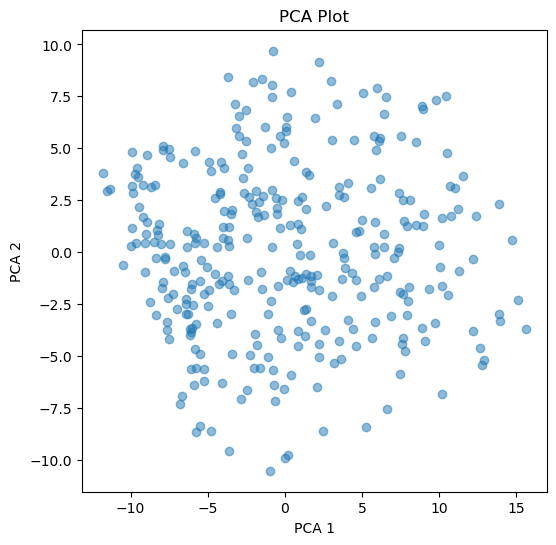

In [109]:
#plt.figure(figsize=(6,6))
#plt.plot(PCA_df['PCA_1'][y_train == 1], PCA_df['PCA_2'][y_train == 1], 'ro', alpha = 0.7, markeredgecolor = 'k')
#plt.plot(PCA_df['PCA_1'][y_train == 0], PCA_df['PCA_2'][y_train == 0], 'bo', alpha = 0.7, markeredgecolor = 'k')
#plt.xlabel('PCA_1')
#plt.ylabel('PCA_2')
#plt.legend(['pCR','not pCR'])

plt.figure(figsize = (6, 6))
plt.scatter(Xs_pca[:, 0], Xs_pca[:, 1], alpha = 0.5)
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('PCA Plot')
plt.show()

In [110]:
#fig = plt.figure(figsize = (10, 10))
#ax = fig.add_subplot(111, projection = '3d')

#ax.scatter(Xs_pca[:, 0], Xs_pca[:, 1], Xs_pca[:, 2], s = 50, alpha = 0.6)

#ax.set_xlabel(f'PCA 1 ({pca.explained_variance_ratio_[0] * 100:.2f} % variance)')
#ax.set_ylabel(f'PCA 2 ({pca.explained_variance_ratio_[1] * 100:.2f} % variance)')
#ax.set_zlabel(f'PCA 3 ({pca.explained_variance_ratio_[2] * 100:.2f} % variance)')

#plt.title('PCA Plot using 3 PCA Features')
#plt.show()

##### LDA (Linear Discriminant Analysis)
This supervised learning method projects data to a new pair of axes that helps split it into different classes. This is done by maximising the variance between data of different classes to separate them, and minimising the mean to keep datapoints within the same class together

Note: Cannot use LDA for RFS Regression because there are no class labels

In [111]:
#from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

#lda = LDA()
#lda.fit(X = X_train, y = y_train)

#lda.predict(X=[X_train.loc[1]])

# Machine Learning Method Development

Steps:
1. Sample New Data
2. Test Data Pipeline
3. Machine Learning Methods

### 1. Process Test Data
1. Preprocessing Pipeline
2. Apply Feature Selection

#### 1. Preprocessing Pipeline
- Create Pipeline that transforms test dataset using every desired method following train-test split
- Apply Pipeline

In [112]:
transformers = {
    "imputer_mode": (imputer_mode, categorical_names),
    "imputer_median": (imputer_median, continuous_names),
    "standard_scaler": (standard_scaler, continuous_names)
}

#outlier_iqr(X_test, categorical_names)
#outlier_iqr(X_test, continuous_names) # this is manual so re implement this in any new notebooks
#for key, value in transformers.items():
#    print(key)
#    X_test[value[1]] = value[0].transform(X_test[value[1]])
#X_test
#X_test[continuous_names] = standard_scaler.transform(X_test[continuous_names])
#X_test_transformed = pd.DataFrame(knn_imputer.transform(X_test), columns = X_test.columns)
#X_test_transformed

,Age,ER,PgR,HER2,TrippleNegative,ChemoGrade,Proliferation,HistologyType,LNStatus,TumourStage,...,original_glszm_SmallAreaHighGrayLevelEmphasis,original_glszm_SmallAreaLowGrayLevelEmphasis,original_glszm_ZoneEntropy,original_glszm_ZonePercentage,original_glszm_ZoneVariance,original_ngtdm_Busyness,original_ngtdm_Coarseness,original_ngtdm_Complexity,original_ngtdm_Contrast,original_ngtdm_Strength
0,1.142582,0.0,0.0,0.0,1.0,3.0,2.0,1.0,0.0,3.0,...,-0.999130,-0.995850,-0.406700,0.617692,-0.921173,-0.592519,0.763432,2.070037,-0.356657,1.061870
1,0.791597,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,3.0,...,0.073474,0.087089,-1.830804,-0.859021,-0.908079,-1.063824,-0.046707,-1.284423,-0.845247,-1.034730
2,-1.083400,0.0,0.0,0.0,1.0,3.0,2.0,1.0,0.0,2.0,...,-0.336631,-0.321053,0.711404,-0.873813,-0.448848,-0.284805,-0.885166,1.242567,2.283593,-0.889360
3,-1.175765,1.0,1.0,0.0,0.0,3.0,3.0,1.0,1.0,2.0,...,0.288392,0.315570,0.369459,1.151865,-0.448863,-0.311887,-0.128928,-0.533611,-0.628138,-0.055182
4,-0.621578,1.0,1.0,1.0,0.0,2.0,2.0,1.0,1.0,2.0,...,0.463895,0.494330,-0.227551,1.817046,-0.879686,-0.874774,2.481318,-0.422538,-0.579796,2.956082
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.241438,1.0,1.0,0.0,0.0,2.0,1.0,2.0,0.0,4.0,...,0.475344,0.505992,0.769332,1.135005,1.232150,3.342572,-0.849732,-0.273526,-0.451127,-0.859974
76,1.133345,0.0,0.0,0.0,1.0,3.0,3.0,1.0,0.0,2.0,...,0.380616,0.409506,0.037563,-0.314956,-0.459482,0.089284,-0.373184,0.805087,0.934485,-0.311471
77,-0.420349,1.0,1.0,0.0,0.0,2.0,1.0,2.0,1.0,3.0,...,0.511956,0.543257,0.816450,1.653648,-0.123478,1.865039,-0.771448,-0.156828,-0.341428,-0.773288
78,-0.791324,0.0,0.0,0.0,1.0,2.0,1.0,1.0,1.0,4.0,...,-1.614940,-1.623087,-1.110371,-1.343436,-0.448848,-0.979604,6.474663,-1.266395,-0.845164,-0.118532


In [113]:
categorical_pipeline = Pipeline(
    steps = [("imputer", SimpleImputer(strategy = 'most-frequent'))]
)

continuous_pipeline = Pipeline(
    steps = [("imputer", SimpleImputer(strategy = 'median')),
             ("standard_scaler", StandardScaler)
    ]
)

preprocessing_pipeline = ColumnTransformer(
    transformers = [("categorical", categorical_pipeline, categorical_names),
                    ("continuous", continuous_pipeline, continuous_names),
    ]
)

#### 2. Apply Feature Selection

### 2. Machine Learning Models

##### Linear:
- Multivariate Linear Regression
- ~~Logistic Regression~~ (Took over 10 min until interrupted) | Classification
- Naïve Bayes (don't forget different types) | Classification
- K-Nearest Neighbour (KNN) | Classification
- Support Vector Classifier/Regressor

##### Non-Linear:
- Kernel Support Vector Classifier/Regressior
- Decision Tree Classifier/Regressor
- Random Forest Classifier/Regressor

##### Deep Learning Models:
- Multilayer Perceptron Classifier/Regressor
- Convolution Neural Networks -------------------------------------------------

In [114]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = {}

In [115]:
lin_reg = LinearRegression()
#lin_reg.fit(X_train_transformed, y_train)
#y_pred_lin = lin_reg.predict(X_test_transformed)

#print(f"Linear Regression MSE: {mean_squared_error(y_test, y_pred_lin)}")
#print(f"Linear Regression MAE: {mean_absolute_error(y_test, y_pred_lin)}")

#### Support Vector Regressor

##### Radial Basis Function (RBF) Kernel

In [116]:
# Kernel SVR (RBF)
svr = SVR(kernel='rbf')
#svr.fit(X_train_transformed, y_train)
#y_pred_svr = svr.predict(X_test_transformed)

#print(f"SVR MSE: {mean_squared_error(y_test, y_pred_svr)}")
#print(f"SVR MAE: {mean_absolute_error(y_test, y_pred_lin)}")

#### Decision Tree Regressor

In [117]:
dt_reg = DecisionTreeRegressor(random_state = r_state)
#dt_reg.fit(X_train_transformed, y_train)
#y_pred_dt = dt_reg.predict(X_test_transformed)

#print(f"Decision Tree MSE: {mean_squared_error(y_test, y_pred_dt)}")
#print(f"Decision Tree MAE: {mean_absolute_error(y_test, y_pred_lin)}")

#### Random Forest Regressor

In [118]:
rf_reg = RandomForestRegressor(n_estimators = 100, random_state = r_state)
#rf_reg.fit(X_train_transformed, y_train)
#y_pred_rf = rf_reg.predict(X_test_transformed)

#print(f"Random Forest MSE: {mean_squared_error(y_test, y_pred_rf)}")
#print(f"Random Forest MAE: {mean_absolute_error(y_test, y_pred_lin)}")

#### Multi Layer Perceptron Regressor

In [119]:
# MLP with 2 hidden layers
mlp_reg = MLPRegressor(hidden_layer_sizes =(100, 50), max_iter = 1000, random_state = r_state)
#mlp_reg.fit(X_train_transformed, y_train)
#y_pred_mlp = mlp_reg.predict(X_test_transformed)

#print(f"MLP MSE: {mean_squared_error(y_test, y_pred_mlp)}")
#print(f"MLP MAE: {mean_absolute_error(y_test, y_pred_lin)}")

# Method Evaluation

- K-Fold Cross-Validation
- Mean Absolute Error

In [120]:
models_reg = {
    "Linear Regression": LinearRegression(),
    "SVR RBF": SVR(kernel = 'rbf'),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state = r_state),
    "Random Forest Regressor": RandomForestRegressor(n_estimators = 100, random_state = r_state),
    "MLP Regressor": MLPRegressor(hidden_layer_sizes =(100, 50), max_iter = 1000, random_state = r_state)
}

In [121]:
k_fold = KFold(n_splits = 5, shuffle = True, random_state = r_state)
print(f"Using K = {k_fold} for K-Fold Cross-Validation")

results = {}

Using K = KFold(n_splits=5, random_state=12, shuffle=True) for K-Fold Cross-Validation


In [122]:
for model_name, model in models_reg.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

scores = cross_val_score(pipeline, x, y, cv = k_fold, scoring = "neg_mean_absolute_error")

mean_score = -(np.mean(scores))
std_dev_score = np.std(scores)

results[model_name] = {"Mean MAE": mean_score, "Std Dev MAE": std_dev_score}
print(f"{model_name}: Mean MAE = {mean_score:,.2f} (+/- {std_dev_score:,.2f})")


/opt/anaconda3/envs/MLE/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/envs/MLE/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


MLP Regressor: Mean MAE = 33.71 (+/- 7.95)


/opt/anaconda3/envs/MLE/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
